### Validation metrics — full pipeline-version comparison

Redoes the point-5 validation metrics (`validation_metrics.ipynb`), which only compared the *original* (leaky, wrong weather) and *temporal* (honest, wrong weather) pipelines — now outdated since the weather-station fix, the model comparison, and the feature engineering ablation. This notebook computes every metric across **all six** pipeline versions produced so far:

1. **Original** — leaky random split, wrong (Upton Co.) weather, RandomForest.
2. **Temporal** — honest seasonal CV, wrong weather, RandomForest.
3. **Weather-fixed** — honest seasonal CV, corrected Coast weather, RandomForest.
4. **XGBoost** — honest seasonal CV, corrected weather, XGBoost.
5. **LightGBM** — honest seasonal CV, corrected weather, LightGBM.
6. **Feature-engineered** — honest seasonal CV, corrected weather, LightGBM + lag/rolling temperature features. Current best-performing pipeline.

Numeric tables report all six for completeness. Plots (load duration curve, diurnal shape) are limited to ERCOT + Original + Weather-fixed + Feature-engineered for legibility — the model-comparison notebook already showed that model choice alone (XGBoost/LightGBM vs RF) does not move the system-level shape, so including all three model variants on every plot would add clutter without new visual information; their numbers are still in every table.

Calibration note: all six use the same `RES_SCALE=1.9`/`COM_SCALE=1.3`/`IND_BASE=4500MW`, not yet re-optimized for the corrected pipeline (open item).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")

PIPELINE_VERSIONS = {
    "Original":            ("final_bus_load_profiles_8760.csv", "final_comstock_bus_load_profiles_8760.csv"),
    "Temporal":            ("final_bus_load_profiles_8760_temporal.csv", "final_comstock_bus_load_profiles_8760_temporal.csv"),
    "Weather-fixed":       ("final_bus_load_profiles_8760_weatherfixed.csv", "final_comstock_bus_load_profiles_8760_weatherfixed.csv"),
    "XGBoost":             ("final_bus_load_profiles_8760_xgboost.csv", "final_comstock_bus_load_profiles_8760_xgboost.csv"),
    "LightGBM":            ("final_bus_load_profiles_8760_lightgbm.csv", "final_comstock_bus_load_profiles_8760_lightgbm.csv"),
    "Feature-engineered":  ("final_bus_load_profiles_8760_featureeng.csv", "final_comstock_bus_load_profiles_8760_featureeng.csv"),
}

PLOT_SUBSET = ["Original", "Weather-fixed", "Feature-engineered"]

res_data, com_data = {}, {}
for name, (res_file, com_file) in PIPELINE_VERSIONS.items():
    res_data[name] = pd.read_csv(exports / res_file, index_col=0, parse_dates=True)
    com_data[name] = pd.read_csv(exports / com_file, index_col=0, parse_dates=True)
    print(f"{name:20s} res={res_data[name].shape}  com={com_data[name].shape}")


Original             res=(8760, 200)  com=(8760, 200)


Temporal             res=(8760, 200)  com=(8760, 200)


Weather-fixed        res=(8760, 200)  com=(8760, 200)


XGBoost              res=(8760, 200)  com=(8760, 200)


LightGBM             res=(8760, 200)  com=(8760, 200)


Feature-engineered   res=(8760, 200)  com=(8760, 200)


#### Load ERCOT actual (same DST-aware parsing used throughout this project)

In [2]:
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_actual = ercot_df_est["COAST"].copy()
ercot_actual.index = ercot_actual.index.tz_localize(None)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3

calibrated_stacks = {}
for name in PIPELINE_VERSIONS:
    total_res_mw = (res_data[name].sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_data[name].sum(axis=1) / 1000) * COM_SCALE
    common_start = max(ercot_actual.index.min(), total_res_mw.index.min())
    common_end = min(ercot_actual.index.max(), total_res_mw.index.max())
    y_ind = pd.Series(IND_BASE_MW, index=total_res_mw.loc[common_start:common_end].index)
    calibrated_stacks[name] = y_ind + total_res_mw.loc[common_start:common_end] + total_com_mw.loc[common_start:common_end]

y_actual = ercot_actual.loc[calibrated_stacks["Original"].index.min():calibrated_stacks["Original"].index.max()]
print(f"Common window: {y_actual.index.min()} to {y_actual.index.max()}  ({len(y_actual)} hours)")


Common window: 2018-01-01 02:00:00 to 2019-01-01 00:00:00  (8759 hours)


#### 1. Pearson correlation and peak (recap, all six versions)

In [3]:
summary_rows = []
for name, stack in calibrated_stacks.items():
    corr = y_actual.corr(stack)
    summary_rows.append({"Pipeline": name, "Pearson_vs_ERCOT": corr, "Peak_MW": stack.max(),
                          "Load_Factor": stack.mean() / stack.max()})

summary_df = pd.DataFrame(summary_rows).set_index("Pipeline").loc[list(PIPELINE_VERSIONS)]
print(f"(ERCOT actual: peak={y_actual.max():,.0f} MW, load factor={y_actual.mean()/y_actual.max():.4f})")
summary_df.round(4)


(ERCOT actual: peak=20,270 MW, load factor=0.6001)


,Pearson_vs_ERCOT,Peak_MW,Load_Factor
Pipeline,,,
Original,0.8818,24417.7193,0.5819
Temporal,0.8907,24604.4068,0.5777
Weather-fixed,0.8986,26114.5874,0.5443
XGBoost,0.8983,26279.4423,0.5409
LightGBM,0.8979,25734.9572,0.5523
Feature-engineered,0.9022,25577.8280,0.5557


#### 2. Coincidence factor / diversity factor, all six versions

Computed on raw (uncalibrated) bus-level kWh — invariant to RES_SCALE/COM_SCALE/IND_BASE.

In [4]:
def coincidence_diversity(bus_df):
    bus_peaks_sum = bus_df.max(axis=0).sum()
    system_peak = bus_df.sum(axis=1).max()
    cf = system_peak / bus_peaks_sum
    return cf, 1 / cf


cf_rows = []
for name in PIPELINE_VERSIONS:
    res_cf, res_df_ = coincidence_diversity(res_data[name])
    com_cf, com_df_ = coincidence_diversity(com_data[name])
    shared = res_data[name].columns.intersection(com_data[name].columns)
    combined_cf, combined_df_ = coincidence_diversity(res_data[name][shared] + com_data[name][shared])
    cf_rows.append({
        "Pipeline": name,
        "CF_Residential": res_cf, "CF_Commercial": com_cf, "CF_Combined": combined_cf,
        "DF_Residential": res_df_, "DF_Commercial": com_df_, "DF_Combined": combined_df_,
    })

cf_df = pd.DataFrame(cf_rows).set_index("Pipeline").loc[list(PIPELINE_VERSIONS)]
cf_df.round(4)


,CF_Residential,CF_Commercial,CF_Combined,DF_Residential,DF_Commercial,DF_Combined
Pipeline,,,,,,
Original,0.9983,0.9984,0.9625,1.0017,1.0016,1.0390
Temporal,0.9957,0.9967,0.9789,1.0043,1.0033,1.0216
Weather-fixed,0.9996,0.9961,0.9857,1.0004,1.0039,1.0145
XGBoost,1.0000,0.9985,0.9896,1.0000,1.0015,1.0105
LightGBM,0.9997,0.9981,0.9885,1.0003,1.0019,1.0117
Feature-engineered,1.0000,0.9985,0.9843,1.0000,1.0015,1.0160


#### 3. Load duration curve (ERCOT + Original + Weather-fixed + Feature-engineered)

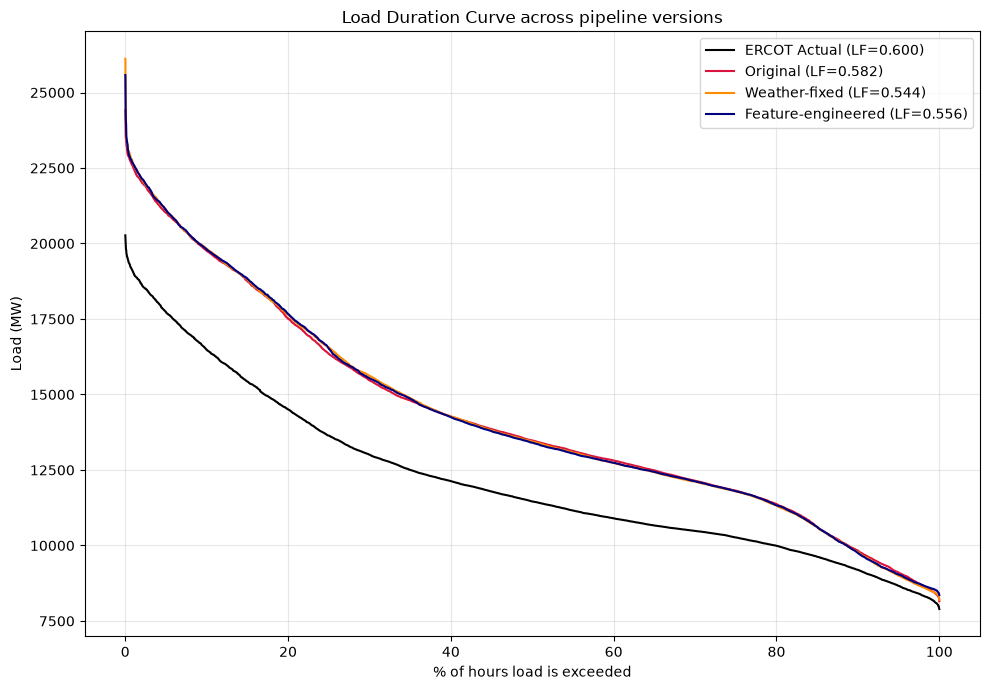

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
colors_plot = {"ERCOT": "black", "Original": "crimson", "Weather-fixed": "darkorange", "Feature-engineered": "navy"}

sorted_actual = np.sort(y_actual.values)[::-1]
pct_hours = np.arange(1, len(sorted_actual) + 1) / len(sorted_actual) * 100
ax.plot(pct_hours, sorted_actual, label=f"ERCOT Actual (LF={y_actual.mean()/y_actual.max():.3f})",
        color=colors_plot["ERCOT"], linewidth=1.5)

for name in PLOT_SUBSET:
    stack = calibrated_stacks[name]
    sorted_desc = np.sort(stack.values)[::-1]
    ax.plot(pct_hours, sorted_desc, label=f"{name} (LF={summary_df.loc[name, 'Load_Factor']:.3f})",
            color=colors_plot[name], linewidth=1.5)

ax.set_xlabel("% of hours load is exceeded")
ax.set_ylabel("Load (MW)")
ax.set_title("Load Duration Curve across pipeline versions")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 4. Diurnal shape by weekday/weekend x summer/winter

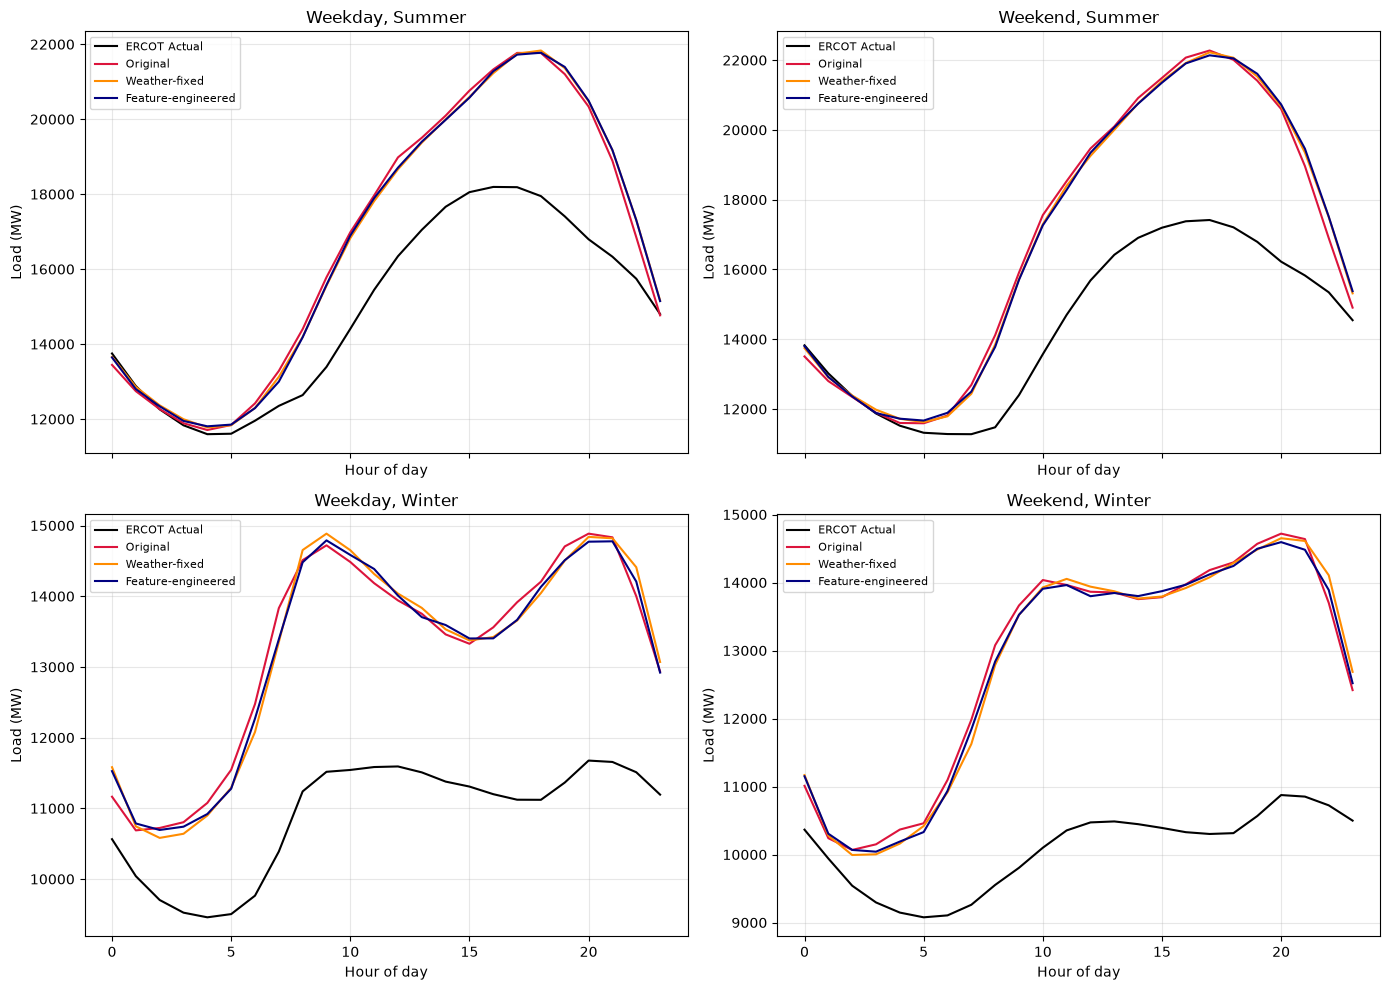

,"Weekday, Summer","Weekend, Summer","Weekday, Winter","Weekend, Winter"
Pipeline,,,,
Original,0.9757,0.9483,0.8739,0.7668
Temporal,0.9808,0.9610,0.9192,0.8047
Weather-fixed,0.9807,0.9600,0.9223,0.8116
XGBoost,0.9809,0.9600,0.9173,0.8090
LightGBM,0.9808,0.9614,0.9192,0.7997
Feature-engineered,0.9801,0.9610,0.9151,0.7978


In [6]:
def diurnal_profile(series, weekday, summer):
    idx = series.index
    is_weekday = idx.dayofweek < 5
    is_summer = idx.month.isin([6, 7, 8])
    is_winter = idx.month.isin([12, 1, 2])
    season_mask = is_summer if summer else is_winter
    day_mask = is_weekday if weekday else ~is_weekday
    sub = series[season_mask & day_mask]
    return sub.groupby(sub.index.hour).mean()


configs = [(True, True, "Weekday, Summer"), (False, True, "Weekend, Summer"),
           (True, False, "Weekday, Winter"), (False, False, "Weekend, Winter")]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
for ax, (weekday, summer, title) in zip(axes.flat, configs):
    actual_prof = diurnal_profile(y_actual, weekday, summer)
    ax.plot(actual_prof.index, actual_prof.values, label="ERCOT Actual", color="black", linewidth=1.5)
    for name in PLOT_SUBSET:
        prof = diurnal_profile(calibrated_stacks[name], weekday, summer)
        ax.plot(prof.index, prof.values, label=name, color=colors_plot[name], linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Load (MW)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

diurnal_corr_rows = []
for name in PIPELINE_VERSIONS:
    row = {"Pipeline": name}
    for weekday, summer, title in configs:
        actual_prof = diurnal_profile(y_actual, weekday, summer)
        model_prof = diurnal_profile(calibrated_stacks[name], weekday, summer)
        row[title] = actual_prof.corr(model_prof)
    diurnal_corr_rows.append(row)

diurnal_corr_df = pd.DataFrame(diurnal_corr_rows).set_index("Pipeline").loc[list(PIPELINE_VERSIONS)]
diurnal_corr_df.round(4)


#### 5. Seasonal monthly bias, all six versions

In [7]:
monthly_actual = y_actual.groupby(y_actual.index.month).mean()

monthly_bias_rows = []
for name in PIPELINE_VERSIONS:
    monthly_model = calibrated_stacks[name].groupby(calibrated_stacks[name].index.month).mean()
    bias_pct = (monthly_model / monthly_actual - 1) * 100
    monthly_bias_rows.append(bias_pct.rename(name))

monthly_bias_df = pd.concat(monthly_bias_rows, axis=1)
monthly_bias_df.index.name = "Month"
print("Monthly bias (%) vs ERCOT actual, all six pipeline versions:")
monthly_bias_df.round(2)


Monthly bias (%) vs ERCOT actual, all six pipeline versions:


,Original,Temporal,Weather-fixed,XGBoost,LightGBM,Feature-engineered
Month,,,,,,
1,29.78,29.67,29.40,29.65,29.59,29.53
2,20.07,20.24,20.26,20.07,20.18,19.96
3,13.35,12.85,12.90,12.73,12.74,12.75
4,15.81,15.72,15.71,15.92,15.88,16.06
5,10.49,10.51,10.62,10.70,10.72,10.65
6,13.86,13.79,13.72,13.70,13.67,13.68
7,13.75,13.93,13.85,13.80,13.83,13.89
8,12.40,12.61,12.67,12.69,12.71,12.70
9,21.42,21.98,21.75,21.93,22.00,21.87


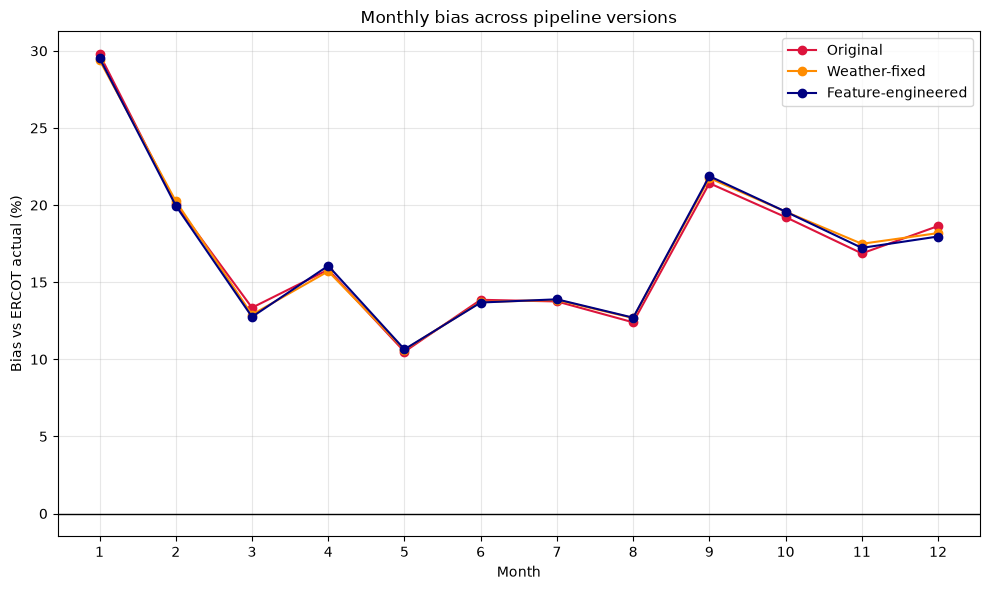

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.axhline(0, color="black", linewidth=1)
for name in PLOT_SUBSET:
    ax.plot(monthly_bias_df.index, monthly_bias_df[name], marker="o", label=name, color=colors_plot[name])
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Bias vs ERCOT actual (%)")
ax.set_title("Monthly bias across pipeline versions")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### 6. Spatial consistency proxy, all six versions

Correlation between per-bus annual energy and per-bus building/sqft count. Building counts and sqft mapping are identical across all six versions (same Census/ArcGIS source) — only the predicted annual energy per bus changes.

In [9]:
final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)
final_bus_counts["total_res_buildings"] = final_bus_counts[
    ["single-family_detached", "single-family_attached",
     "multi-family_with_2_-_4_units", "multi-family_with_5plus_units", "mobile_home"]
].sum(axis=1)

bus_sqft = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft.index = bus_sqft.index.astype(str)
bus_sqft["total_sqft"] = bus_sqft.sum(axis=1)

spatial_rows = []
for name in PIPELINE_VERSIONS:
    res_annual = res_data[name].sum(axis=0)
    res_annual.index = res_annual.index.astype(str)
    com_annual = com_data[name].sum(axis=0)
    com_annual.index = com_annual.index.astype(str)

    res_check = final_bus_counts.set_index("Bus_Number")["total_res_buildings"].to_frame()
    res_check["annual_energy_kwh"] = res_annual
    res_corr = res_check["total_res_buildings"].corr(res_check["annual_energy_kwh"])

    com_check = bus_sqft[["total_sqft"]].copy()
    com_check["annual_energy_kwh"] = com_annual
    com_corr = com_check["total_sqft"].corr(com_check["annual_energy_kwh"])

    spatial_rows.append({"Pipeline": name, "Residential_corr": res_corr, "Commercial_corr": com_corr})

spatial_df = pd.DataFrame(spatial_rows).set_index("Pipeline").loc[list(PIPELINE_VERSIONS)]
spatial_df.round(4)


,Residential_corr,Commercial_corr
Pipeline,,
Original,0.9479,0.8917
Temporal,0.9479,0.8918
Weather-fixed,0.9479,0.8917
XGBoost,0.9479,0.8917
LightGBM,0.9479,0.8917
Feature-engineered,0.9479,0.8917


#### Summary — an honest, not purely monotonic, picture

- **Pearson correlation**: improves essentially monotonically (0.8818 -> 0.9022) across every fix, confirming the main narrative.
- **Load factor**: does NOT improve monotonically. ERCOT actual is 0.600; Original is 0.582 (closest of all six), and the weather fix actually moves it further away (0.544) before feature engineering partially recovers it (0.556). The corrections that improved hour-by-hour correlation made the estimated stack slightly peakier relative to actual than the original (uncorrected) pipeline was — worth being upfront about rather than implying every metric improved together.
- **Coincidence factor (combined res+com)**: trends from 0.963 toward 0.99 as fixes are applied — i.e. *less* diversity between residential and commercial peak timing, not more. Plausibly because better models converge on the same dominant driver (temperature), so res and com peaks align more tightly. Within-sector CF stays pinned near 1.0 throughout, as expected (single zone-wide weather series, unchanged by any fix tried so far).
- **Diurnal shape, winter weekend (the previously-identified weak spot)**: improves from 0.767 (Original) to a peak of 0.812 (Weather-fixed), but then *drifts back down* through XGBoost (0.809), LightGBM (0.800), and Feature-engineered (0.798) — still well above the original 0.767, but the weather fix, not the later model/feature refinements, is what actually fixed this particular metric. The later refinements improved the archetype-level R2 and the overall Pearson correlation without further improving this specific shape sub-metric.
- **Monthly bias**: broadly stable across all six versions (differences mostly under 1 percentage point per month), no single fix dominates here.
- **Spatial proxy**: identical across all six versions (0.9479 / 0.8917-0.8918), as expected — building counts and sqft mapping never changed, only the predicted energy per bus did, and this proxy is insensitive to that. Confirms it was always primarily a plumbing check, not a genuine spatial validation.

**Takeaway for the paper**: the temporal-leakage and weather-geography fixes are the ones that improved secondary shape metrics (load duration curve shape, winter-weekend diurnal match), not just the headline correlation. The later model-choice and feature-engineering refinements mainly improved per-archetype accuracy and the aggregate Pearson number, while leaving (or slightly trading off) some of these secondary metrics. This is a more nuanced and more defensible story than "every fix improved everything."